In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import json

with open('api_troll_farm.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

df = pd.json_normalize(data)

print(df)

       account_id metadata.last_ip metadata.payment_hash  \
0     TROLL_BOT_1    104.28.19.112   VISA-4455-XXXX-9090   
1    real_user_14    189.168.1.196     MC-8573-XXXX-1111   
2    real_user_13    189.168.1.184                   NaN   
3     TROLL_BOT_5    104.28.19.112   VISA-4455-XXXX-9090   
4    real_user_12     189.168.1.51     MC-4432-XXXX-1111   
5    real_user_11    189.168.1.231     MC-5554-XXXX-1111   
6    real_user_15    189.168.1.186                   NaN   
7     real_user_8    189.168.1.246     MC-5803-XXXX-1111   
8    real_user_10     189.168.1.68                   NaN   
9     troll_bot_1    104.28.19.112   VISA-4455-XXXX-9090   
10    TROLL_BOT_4    104.28.19.112   VISA-4455-XXXX-9090   
11    TROLL_BOT_6    104.28.19.112   VISA-4455-XXXX-9090   
12    real_user_6     189.168.1.36     MC-2584-XXXX-1111   
13    real_user_4    189.168.1.160     MC-1106-XXXX-1111   
14    real_user_9    189.168.1.230     MC-4150-XXXX-1111   
15    real_user_1    189.168.1.238      

In [2]:
df['account_id'] = df['account_id'].str.upper()

df_social = df[['account_id', 'activity.retweets']].dropna().copy()
df_social = df_social.explode('activity.retweets')
df_social['activity.retweets'] = df_social['activity.retweets'].str.upper()

df_social = df_social[df_social['account_id'] != df_social['activity.retweets']]
df_social['Relacion'] = 'Retweet'
df_social = df_social.rename(columns={'account_id': 'Origen', 'activity.retweets': 'Destino'})[['Origen', 'Destino', 'Relacion']]

display(df_social.head())


,Origen,Destino,Relacion
0,TROLL_BOT_1,REAL_USER_11,Retweet
1,REAL_USER_14,REAL_USER_15,Retweet
1,REAL_USER_14,REAL_USER_11,Retweet
2,REAL_USER_13,REAL_USER_3,Retweet
2,REAL_USER_13,REAL_USER_9,Retweet


In [3]:
df_infra = df[['account_id', 'metadata.payment_hash']].dropna().drop_duplicates().copy()
df_cards = pd.merge(df_infra, df_infra, on='metadata.payment_hash')
df_cards = df_cards[df_cards['account_id_x'] != df_cards['account_id_y']].copy()
df_cards['Relacion'] = 'Misma_Tarjeta'
df_cards = df_cards.rename(columns={'account_id_x': 'Origen', 'account_id_y': 'Destino'})[['Origen', 'Destino', 'Relacion']]

display(df_cards.head(50))




,Origen,Destino,Relacion
1,TROLL_BOT_1,TROLL_BOT_5,Misma_Tarjeta
2,TROLL_BOT_1,TROLL_BOT_4,Misma_Tarjeta
3,TROLL_BOT_1,TROLL_BOT_6,Misma_Tarjeta
4,TROLL_BOT_1,TROLL_BOT_3,Misma_Tarjeta
5,TROLL_BOT_1,TROLL_BOT_2,Misma_Tarjeta
7,TROLL_BOT_5,TROLL_BOT_1,Misma_Tarjeta
9,TROLL_BOT_5,TROLL_BOT_4,Misma_Tarjeta
10,TROLL_BOT_5,TROLL_BOT_6,Misma_Tarjeta
11,TROLL_BOT_5,TROLL_BOT_3,Misma_Tarjeta
12,TROLL_BOT_5,TROLL_BOT_2,Misma_Tarjeta


In [4]:
df_master = pd.concat([df_social, df_cards], ignore_index=True)


MDG = nx.from_pandas_edgelist(
    df_master, 
    source='Origen', 
    target='Destino', 
    edge_attr='Relacion', 
    create_using=nx.MultiDiGraph()
)
print("Nodos totales:", MDG.number_of_nodes())
print("Aristas totales:", MDG.number_of_edges())

Nodos totales: 21
Aristas totales: 67


In [5]:
aristas_tarjeta = [
    (u, v) for u, v, k, d in MDG.edges(keys=True, data=True) 
    if d.get('Relacion') == 'Misma_Tarjeta'
]

G_tarjeta = nx.Graph()
G_tarjeta.add_edges_from(aristas_tarjeta)

comunidades = list(nx.connected_components(G_tarjeta))
anillo_fraude = sorted([list(c) for c in comunidades if len(c) > 1][0])
hash_tarjeta = df[df['account_id'].isin(anillo_fraude)]['metadata.payment_hash'].unique()[0]

print("Anillo de fraude:", anillo_fraude)
print("Hash tarjeta:", hash_tarjeta)

Anillo de fraude: ['TROLL_BOT_1', 'TROLL_BOT_2', 'TROLL_BOT_3', 'TROLL_BOT_4', 'TROLL_BOT_5', 'TROLL_BOT_6']
Hash tarjeta: VISA-4455-XXXX-9090


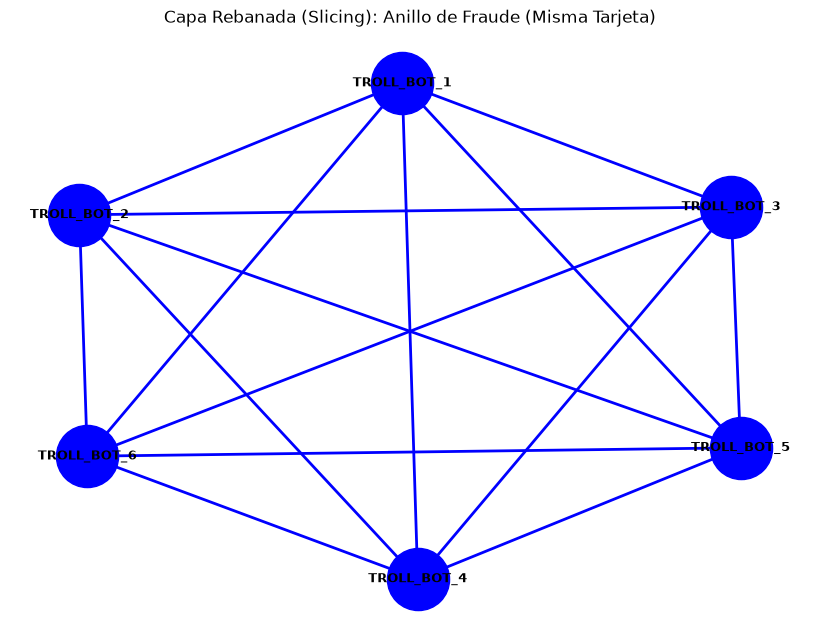

In [ ]:
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G_tarjeta, seed=42)

nx.draw(
    G_tarjeta, 
    pos, 
    with_labels=True, 
    node_color='blue', 
    node_size=2000, 
    font_size=9, 
    font_weight='bold', 
    edge_color='blue', 
    width=2
)

plt.title('Capa Rebanada (Slicing): Anillo de Fraude (Misma Tarjeta)')
plt.show()

El Veredicto

1. ¿Cuáles son los nombres exactos (account_id) de los bots que conforman el anillo de fraude?
R: TROLL_BOT_1 , TROLL_BOT_2, TROLL_BOT_3, TROLL_BOT_4, TROLL_BOT_5 y TROLL_BOT_6.

2. ¿Cuál es el Hash de la tarjeta de crédito comprometida que el equipo de soporte técnico debe bloquear ahora mismo?**
R: VISA-4455-XXXX-9090

3. Si tuvieran que entrenar un modelo de predicción, ¿cómo le pasarían este descubrimiento al modelo tabular (La matriz X de entrenamiento)?**
R:
- Feature binario: Columna en_anillo_fraude 
- Grado por capa**: Columna degree_misma_tarjeta 
- Métricas de red: in_degree y out_degree de retweets para detectar actividad no orgánica, centralidades  y Node Embeddings  agregados como columnas numéricas a la matriz X.